In [1]:
import os
import platform
import sys

print("Operating system:", platform.platform())
print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Current working directory:", os.getcwd())

Operating system: Windows-11-10.0.26300-SP0
Python executable: C:\Python314\python.exe
Python version: 3.14.4 (tags/v3.14.4:23116f9, Apr  7 2026, 14:10:54) [MSC v.1944 64 bit (AMD64)]
Current working directory: C:\Users\Akhilesh


In [ ]:
#!pip install tensorflow


In [2]:
import os
import shutil
import zipfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

ZIP_PATH = Path(r"C:\Users\Akhilesh\Downloads\skin_data.zip")

EXTRACT_TO = Path(r"C:\Users\Akhilesh\Datasets\skin_data")

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

EXTRACT_TO.parent.mkdir(parents=True, exist_ok=True)

print("ZIP path:", ZIP_PATH)
print("Extraction folder:", EXTRACT_TO)
print("TensorFlow version:", tf.__version__)

C:\Users\Akhilesh\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ZIP path: C:\Users\Akhilesh\Downloads\skin_data.zip
Extraction folder: C:\Users\Akhilesh\Datasets\skin_data
TensorFlow version: 2.22.0-rc0


In [6]:
MARKER = EXTRACT_TO / ".extraction_complete"

if not ZIP_PATH.is_file():
    raise FileNotFoundError(
        f"ZIP file not found: {ZIP_PATH}\n"
        "Check ZIP_PATH and make sure the file is downloaded."
    )

if MARKER.exists():
    print("Dataset extraction was previously completed.")

else:
    zip_size = ZIP_PATH.stat().st_size

    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        entries = zf.infolist()
        uncompressed_size = sum(item.file_size for item in entries)
        file_count = sum(not item.is_dir() for item in entries)

        free_bytes = shutil.disk_usage(EXTRACT_TO.parent).free

        print(f"ZIP size: {zip_size / 1024**3:.2f} GB")
        print(f"Extracted size: {uncompressed_size / 1024**3:.2f} GB")
        print(f"Files in ZIP: {file_count:,}")
        print(f"Free disk space: {free_bytes / 1024**3:.2f} GB")

        if free_bytes < uncompressed_size + int(1.5 * 1024**3):
            raise RuntimeError(
                "Not enough free disk space. Free up space or "
                "choose a drive with more available storage."
            )

        print("Extracting dataset. Please wait...")
        start = time.time()

        zf.extractall(EXTRACT_TO)

    MARKER.write_text("Extraction completed successfully.")

    print(f"Extraction completed in {(time.time() - start) / 60:.2f} minutes.")

print("Extraction folder:", EXTRACT_TO)
print("Top-level contents:", [p.name for p in EXTRACT_TO.iterdir()][:20])

ZIP size: 5.19 GB
Extracted size: 5.20 GB
Files in ZIP: 27,153
Free disk space: 24.97 GB
Extracting dataset. Please wait...
Extraction completed in 1.03 minutes.
Extraction folder: C:\Users\Akhilesh\Datasets\skin_data
Top-level contents: ['.extraction_complete', 'skin data']


In [7]:
def find_class_root(base_path):
    all_dirs = []
    child_dirs = {}
    image_counts = {}

    for root, dirs, files in os.walk(base_path):
        current = Path(root)
        all_dirs.append(current)
        child_dirs[current] = [current / name for name in dirs]

        image_counts[current] = sum(
            1 for name in files
            if Path(name).suffix.lower() in IMAGE_EXTENSIONS
        )

    for current in sorted(
        all_dirs,
        key=lambda path: len(path.parts),
        reverse=True
    ):
        if current != base_path:
            image_counts[current.parent] = (
                image_counts.get(current.parent, 0)
                + image_counts[current]
            )

    candidates = []

    for current in all_dirs:
        class_count = sum(
            image_counts.get(child, 0) > 0
            for child in child_dirs[current]
        )

        if class_count >= 2:
            candidates.append((class_count, len(current.parts), current))

    if not candidates:
        raise ValueError(
            "Could not find a folder containing at least two "
            "disease-class folders with images."
        )

    return max(candidates, key=lambda item: (item[0], item[1]))[2]


dataset_path = find_class_root(EXTRACT_TO)

class_names = sorted([
    folder.name
    for folder in dataset_path.iterdir()
    if folder.is_dir()
    and any(
        file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
        for file in folder.rglob("*")
    )
])

print("Dataset folder:", dataset_path)
print("Number of classes:", len(class_names))
print("Classes:", class_names)

if len(class_names) < 2:
    raise ValueError("At least two disease-class folders are required.")

Dataset folder: C:\Users\Akhilesh\Datasets\skin_data\skin data
Number of classes: 10
Classes: ['1. Eczema 1677', '10. Warts Molluscum and other Viral Infections - 2103', '2. Melanoma 15.75k', '3. Atopic Dermatitis - 1.25k', '4. Basal Cell Carcinoma (BCC) 3323', '5. Melanocytic Nevi (NV) - 7970', '6. Benign Keratosis-like Lesions (BKL) 2624', '7. Psoriasis pictures Lichen Planus and related diseases - 2k', '8. Seborrheic Keratoses and other Benign Tumors - 1.8k', '9. Tinea Ringworm Candidiasis and other Fungal Infections - 1.7k']


Checking for empty image files...
Empty files removed: 0
Total usable image files: 27153

Images per class:
1. Eczema 1677                                                      1677
10. Warts Molluscum and other Viral Infections - 2103               2103
2. Melanoma 15.75k                                                  3140
3. Atopic Dermatitis - 1.25k                                        1257
4. Basal Cell Carcinoma (BCC) 3323                                  3323
5. Melanocytic Nevi (NV) - 7970                                     7970
6. Benign Keratosis-like Lesions (BKL) 2624                         2079
7. Psoriasis pictures Lichen Planus and related diseases - 2k       2055
8. Seborrheic Keratoses and other Benign Tumors - 1.8k              1847
9. Tinea Ringworm Candidiasis and other Fungal Infections - 1.7k    1702


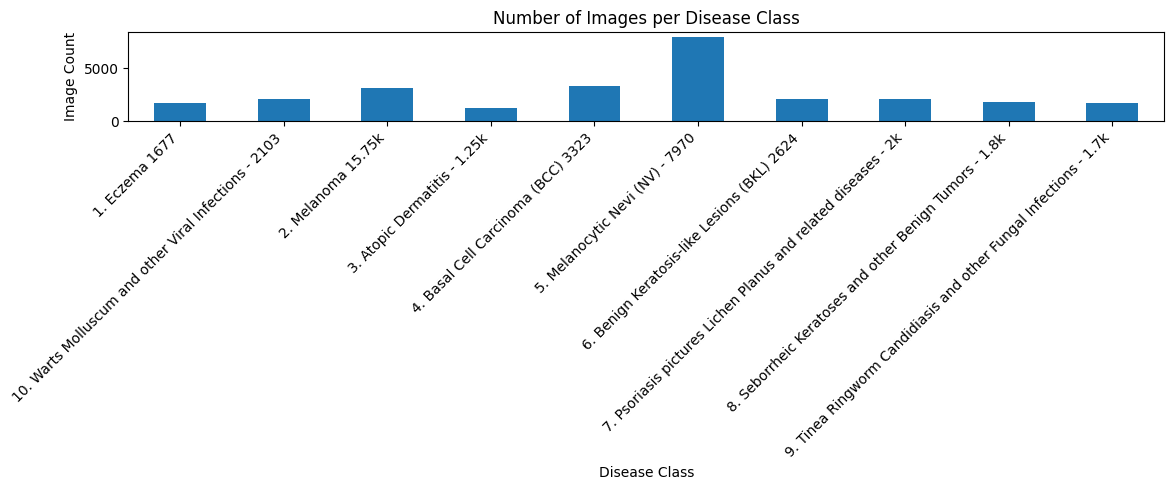

In [8]:
empty_files = []
file_paths = []
labels = []

print("Checking for empty image files...")

for class_index, class_name in enumerate(class_names):
    class_folder = dataset_path / class_name

    for file in class_folder.rglob("*"):
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS:
            if file.stat().st_size == 0:
                empty_files.append(file)
            else:
                file_paths.append(str(file))
                labels.append(class_index)

for file in empty_files:
    file.unlink()

print("Empty files removed:", len(empty_files))
print("Total usable image files:", len(file_paths))

class_counts = pd.Series(
    [class_names[label] for label in labels]
).value_counts().reindex(class_names, fill_value=0)

print("\nImages per class:")
print(class_counts.to_string())

plt.figure(figsize=(12, 5))
class_counts.plot(kind="bar")
plt.title("Number of Images per Disease Class")
plt.xlabel("Disease Class")
plt.ylabel("Image Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

if len(file_paths) == 0:
    raise ValueError("No usable images were found.")

In [9]:
gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", gpus)

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled for:", gpu)
    except RuntimeError as error:
        print(error)

if not gpus:
    print(
        "No TensorFlow GPU detected. Training will use the CPU "
        "unless the local TensorFlow/GPU configuration is fixed."
    )

TensorFlow version: 2.22.0-rc0
Available GPUs: []
No TensorFlow GPU detected. Training will use the CPU unless the local TensorFlow/GPU configuration is fixed.


In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))
print("Total images:", len(X_train) + len(X_val) + len(X_test))

Training images: 19007
Validation images: 4073
Testing images: 4073
Total images: 27153


In [11]:
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(class_names)

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(label, tf.int32)


def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(paths), 10000),
            seed=SEED
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print("Training, validation and testing pipelines are ready.")

Training, validation and testing pipelines are ready.


In [12]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Layer (type)          ┃ Output Shape    ┃  Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ conv2d (Conv2D)       │ (None, 126,     │      896 │
│                       │ 126, 32)        │          │
├───────────────────────┼─────────────────┼──────────┤
│ max_pooling2d         │ (None, 63, 63,  │        0 │
│ (MaxPooling2D)        │ 32)             │          │
├───────────────────────┼─────────────────┼──────────┤
│ conv2d_1 (Conv2D)     │ (None, 61, 61,  │   18,496 │
│                       │ 64)             │          │
├───────────────────────┼─────────────────┼──────────┤
│ max_pooling2d_1       │ (None, 30, 30,  │        0 │
│ (MaxPooling2D)        │ 64)             │          │
├───────────────────────┼─────────────────┼──────────┤
│ conv2d_2 (Conv2D)     │ (None, 28, 28,  │   73,856 │
│                       │ 128)            │          │
├───────────────────────┼─────────────────┼──────────┤
│ max_pooling2d_2       │ (None, 14, 14,  │        0 │
│ (MaxPooling2D)        │ 128)            │          │
├───────────────────────┼─────────────────┼──────────┤
│ flatten (Flatten)     │ (None, 25088)   │        0 │
├───────────────────────┼─────────────────┼──────────┤
│ dense (Dense)         │ (None, 128)     │ 3,211,3… │
├───────────────────────┼─────────────────┼──────────┤
│ dropout (Dropout)     │ (None, 128)     │        0 │
├───────────────────────┼─────────────────┼──────────┤
│ dense_1 (Dense)       │ (None, 10)      │    1,290 │
└───────────────────────┴─────────────────┴──────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

BEST_MODEL_PATH = EXTRACT_TO.parent / "best_skin_cnn.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),

    ModelCheckpoint(
        str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks
)

print("Best model saved at:", BEST_MODEL_PATH)

Epoch 1/25


C:\Users\Akhilesh\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1188/1188 ━━━━━━━━━━━━━━━━━━━━ 387s 325ms/step - accuracy: 0.4218 - loss: 1.5720 - val_accuracy: 0.5306 - val_loss: 1.2338 - learning_rate: 0.0010
Epoch 2/25
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 265s 223ms/step - accuracy: 0.5029 - loss: 1.2873 - val_accuracy: 0.5620 - val_loss: 1.1100 - learning_rate: 0.0010
Epoch 3/25
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 205s 172ms/step - accuracy: 0.5368 - loss: 1.1963 - val_accuracy: 0.5733 - val_loss: 1.0794 - learning_rate: 0.0010
Epoch 4/25
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 232s 195ms/step - accuracy: 0.5535 - loss: 1.1429 - val_accuracy: 0.6030 - val_loss: 1.0220 - learning_rate: 0.0010
Epoch 5/25
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 277s 208ms/step - accuracy: 0.5652 - loss: 1.1018 - val_accuracy: 0.5969 - val_loss: 1.0113 - learning_rate: 0.0010
Epoch 6/25
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 226s 191ms/step - accuracy: 0.5823 - loss: 1.0626 - val_accuracy: 0.6050 - val_loss: 1.0183 - learning_rate: 0.0010
Epoch 7/25
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 224s 189ms/step - acc

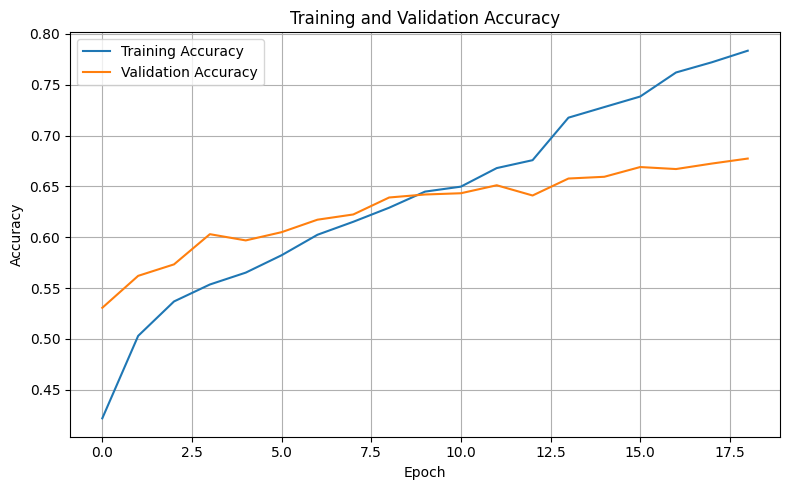

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

y_true = np.array(y_test)

y_probabilities = model.predict(test_ds)
y_pred = np.argmax(y_probabilities, axis=1)

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

255/255 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - accuracy: 0.6595 - loss: 0.9495
Test Loss: 0.9495
Test Accuracy: 65.95%
255/255 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step

Classification Report:

                                                                  precision    recall  f1-score   support

                                                  1. Eczema 1677       0.45      0.46      0.46       252
           10. Warts Molluscum and other Viral Infections - 2103       0.47      0.42      0.44       315
                                              2. Melanoma 15.75k       0.87      0.86      0.87       471
                                    3. Atopic Dermatitis - 1.25k       0.31      0.31      0.31       189
                              4. Basal Cell Carcinoma (BCC) 3323       0.71      0.83      0.76       499
                                 5. Melanocytic Nevi (NV) - 7970       0.87      0.92      0.89      1195
                     6. Benign Keratosis-like Lesions (BKL) 2624       0.

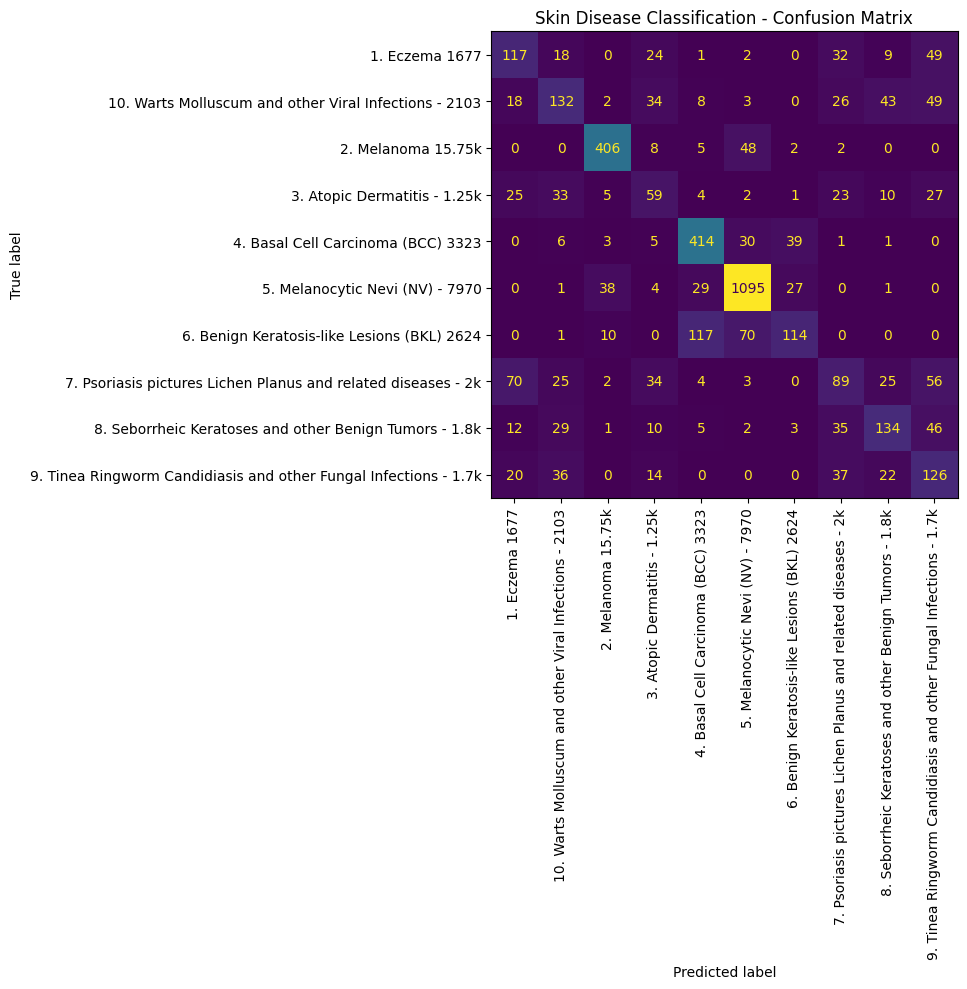

In [16]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))

display_matrix.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title("Skin Disease Classification - Confusion Matrix")
plt.tight_layout()
plt.show()